In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Model saving
import joblib

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_excel("Dry_Bean_Dataset.xlsx")

# Display first five rows
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
df.describe()

Dataset Shape: (13611, 17)

Columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-nu

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


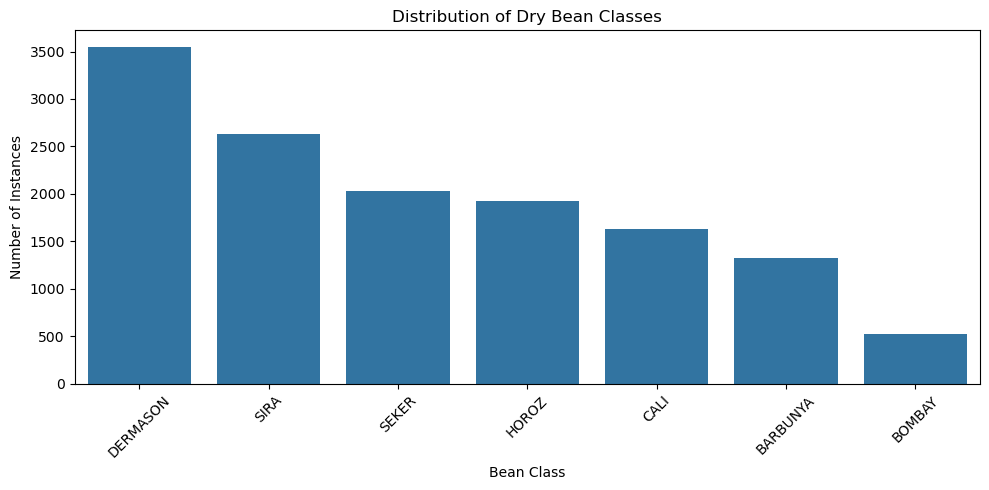

In [4]:
# Distribution of target classes
print(df["Class"].value_counts())

# Visualize class distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Instances")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
# Separate features and target variable

X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

Features shape: (13611, 16)
Target shape: (13611,)

Input features:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Target classes:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


In [6]:
# Encode categorical target labels

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

# Display class encoding
class_mapping = dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
))

print("Class Encoding:")
print(class_mapping)

Class Encoding:
{'BARBUNYA': np.int64(0), 'BOMBAY': np.int64(1), 'CALI': np.int64(2), 'DERMASON': np.int64(3), 'HOROZ': np.int64(4), 'SEKER': np.int64(5), 'SIRA': np.int64(6)}


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (10888, 16)
Testing set shape: (2723, 16)


In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}

print("Five models defined successfully!")

for name in models:
    print(name)

Five models defined successfully!
Logistic Regression
Decision Tree
KNN
Naive Bayes
Support Vector Machine


In [9]:
for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    print(f"{name} trained successfully!\n")

print("All models trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training KNN...
KNN trained successfully!

Training Naive Bayes...
Naive Bayes trained successfully!

Training Support Vector Machine...
Support Vector Machine trained successfully!

All models trained successfully!


In [10]:
# Store evaluation results
results = []

for name, model in models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Get prediction probabilities
    y_prob = model.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="macro"
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro"
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro"
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store results
    results.append({
        "ML Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Display results
results_df = results_df.set_index("ML Model")

print("CLASSIFICATION MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

CLASSIFICATION MODEL PERFORMANCE COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model,,,,,,
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Naive Bayes,0.7639,0.9672,0.7744,0.7694,0.7677,0.7154
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


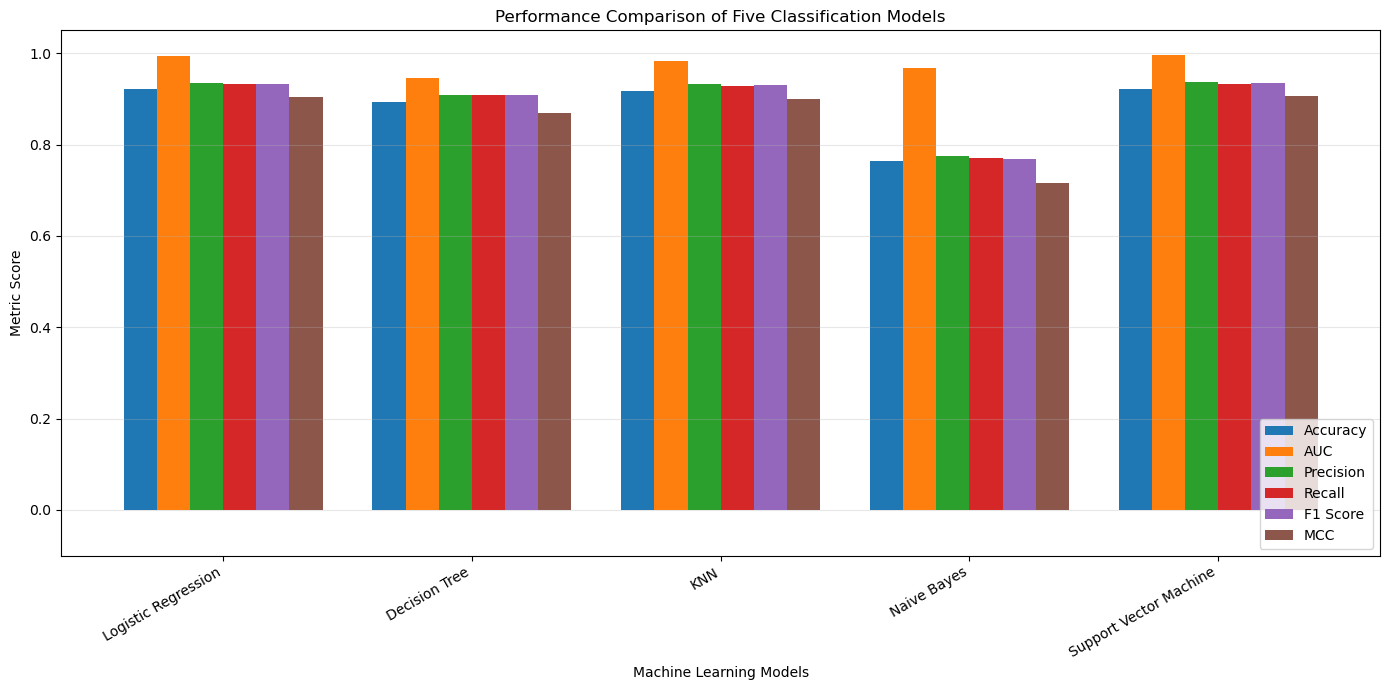

In [11]:
# Plot comparison of evaluation metrics

metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

results_df[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Metric Score")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.ylim(-0.1, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Identify the model with the highest accuracy

best_model = results_df["Accuracy"].idxmax()
best_accuracy = results_df["Accuracy"].max()

print("Best Performing Model:", best_model)
print("Accuracy:", round(best_accuracy, 4))

# Rank all models by accuracy
print("\nModel Ranking:")
display(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    ).round(4)
)

Best Performing Model: Support Vector Machine
Accuracy: 0.9221

Model Ranking:


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model,,,,,,
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
Naive Bayes,0.7639,0.9672,0.7744,0.7694,0.7677,0.7154


In [13]:
import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# Save each trained model
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

for name, model in models.items():

    file_path = os.path.join("models", model_files[name])

    joblib.dump(model, file_path)

    print(f"{name} saved successfully at {file_path}")

# Save label encoder
joblib.dump(label_encoder, "models/label_encoder.joblib")

print("\nAll models and label encoder saved successfully!")

Logistic Regression saved successfully at models\logistic_regression.joblib
Decision Tree saved successfully at models\decision_tree.joblib
KNN saved successfully at models\knn.joblib
Naive Bayes saved successfully at models\naive_bayes.joblib
Support Vector Machine saved successfully at models\svm.joblib

All models and label encoder saved successfully!


In [14]:
# Create test dataset with original class labels

test_data = X_test.copy()

test_data["Class"] = label_encoder.inverse_transform(y_test)

# Save test data
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")

print("\nTest dataset shape:", test_data.shape)

print("\nFirst five records:")
display(test_data.head())

Test dataset saved successfully!

Test dataset shape: (2723, 17)

First five records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
12803,36002,700.889,257.888986,178.268649,1.446631,0.722605,36368,214.100841,0.797386,0.989936,0.920954,0.830205,0.007163,0.002099,0.689241,0.997078,DERMASON
3713,183825,1594.423,582.225240,402.762055,1.445581,0.722124,185116,483.790512,0.797852,0.993026,0.908672,0.830934,0.003167,0.000931,0.690451,0.998102,BOMBAY
8974,45595,801.717,301.092828,193.505323,1.555992,0.766138,46054,240.942643,0.769926,0.990033,0.891425,0.800227,0.006604,0.001670,0.640363,0.996401,SIRA
1743,45084,763.811,261.138204,219.977872,1.187111,0.538882,45425,239.588672,0.773098,0.992493,0.971092,0.917478,0.005792,0.002532,0.841767,0.999271,SEKER
2303,61645,952.199,335.139136,235.843970,1.421021,0.710478,62499,280.158619,0.795522,0.986336,0.854382,0.835947,0.005437,0.001638,0.698808,0.993020,BARBUNYA


In [15]:
# Save model comparison results

results_df.to_csv("model_comparison.csv")

print("Model comparison saved successfully!")

Model comparison saved successfully!



Confusion Matrix: Logistic Regression


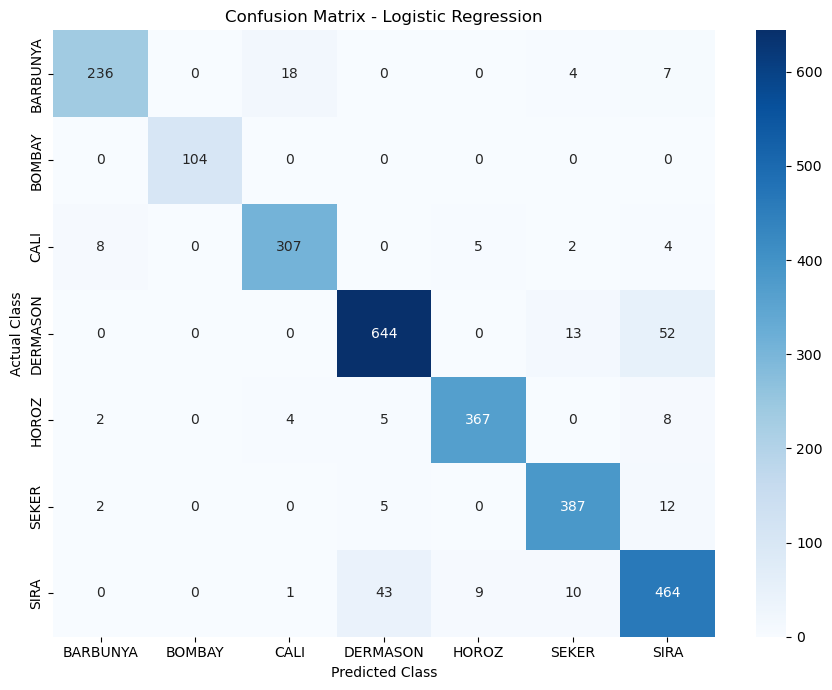


Confusion Matrix: Decision Tree


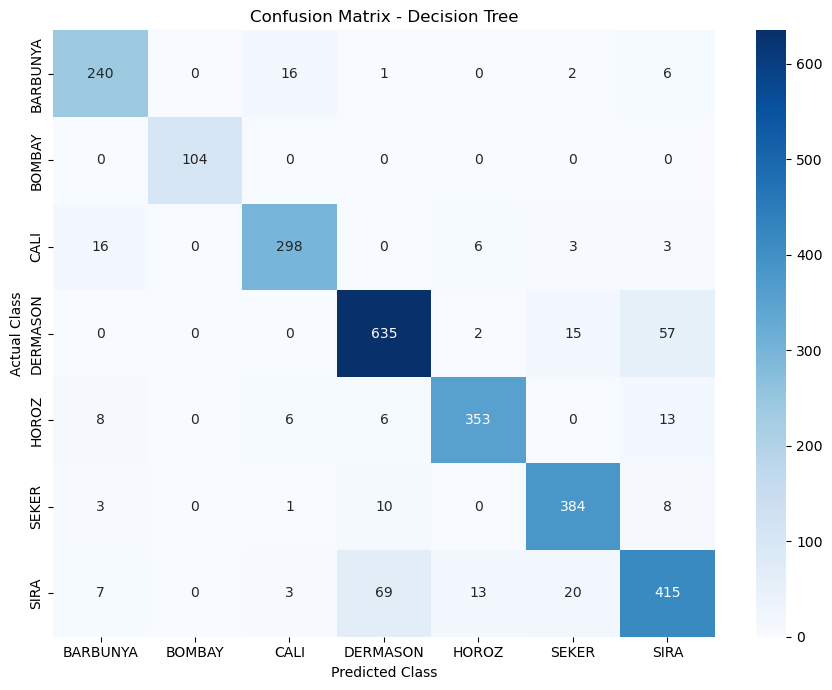


Confusion Matrix: KNN


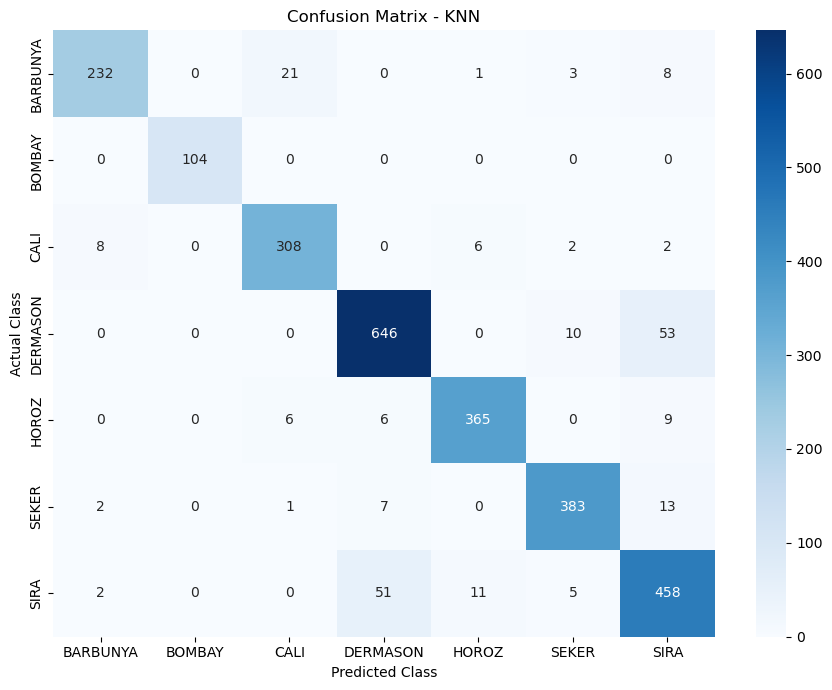


Confusion Matrix: Naive Bayes


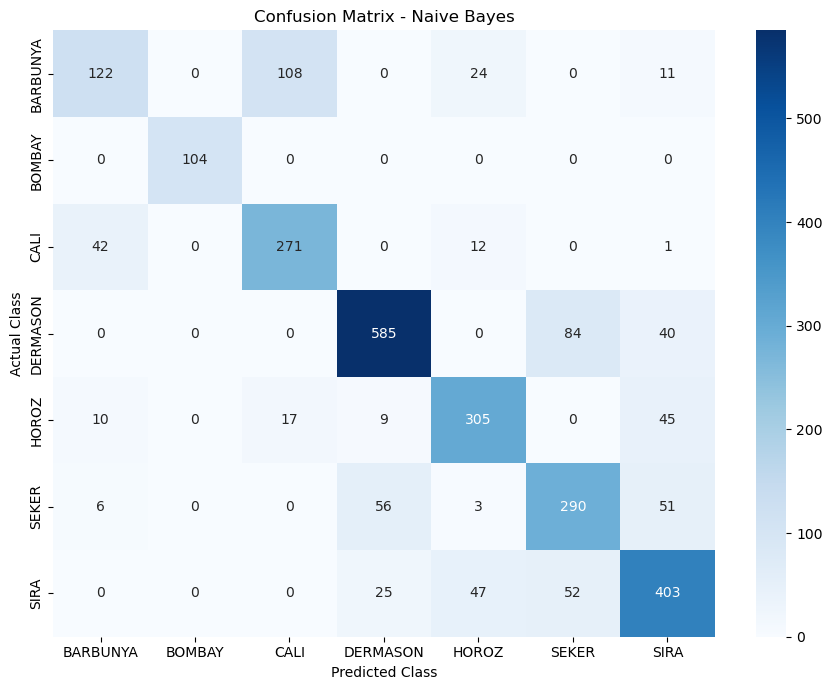


Confusion Matrix: Support Vector Machine


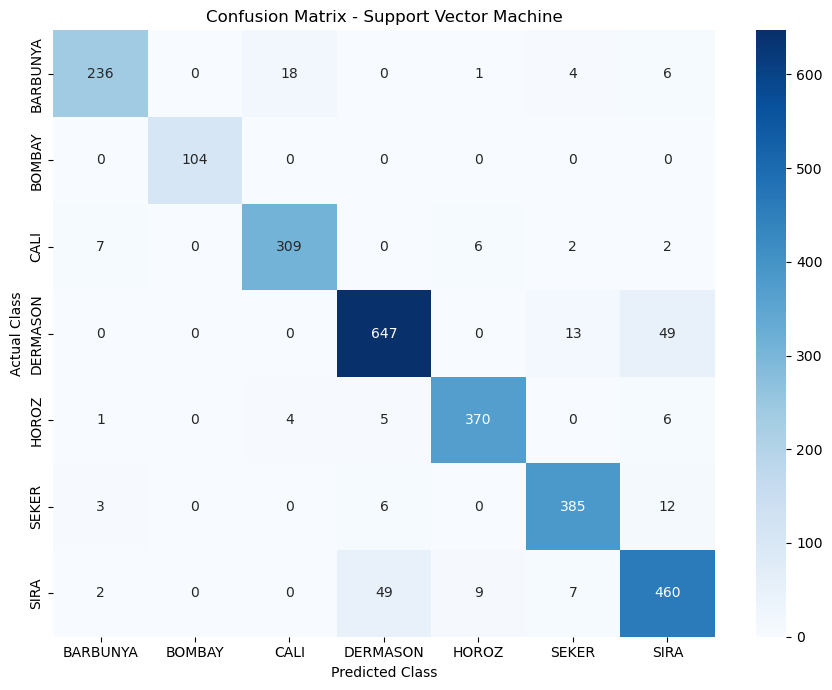

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = label_encoder.classes_

for name, model in models.items():

    y_pred = model.predict(X_test)

    print(f"\nConfusion Matrix: {name}")

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()